# Jeddah flash floods — quick data check

**Goal:** find **which places in Jeddah are susceptible to flash-flood water, and why.**
Because this is a question about *where*, every test is done on places the model has not seen (whole 1 km
blocks, `block_id`). Both storms (21 Nov 2017 and 24 Nov 2022) are used together as one dataset.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42

# project folder (works from the project root or from notebooks/)
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
df = pd.read_parquet(ROOT / "data/processed/jeddah_flood_ml.parquet")             # default file
em = pd.read_parquet(ROOT / "data/processed/jeddah_flood_ml_elev_matched.parquet")  # harder variant
dd = pd.read_csv(ROOT / "data_dictionary.csv")

STORM = {"JED_20171121": "2017-11-21", "JED_20221124": "2022-11-24"}
for d in (df, em):
    d["storm"] = d["event_id"].map(STORM)

# columns allowed as model inputs, and columns that must never be used
INPUTS = dd.loc[dd.use_as_model_input == "yes", "column"].tolist()
DO_NOT_USE = dd.loc[dd.use_as_model_input == "NO", "column"].tolist()
print(f"default file: {len(df):,} rows | elevation-matched file: {len(em):,} rows | {df.shape[1] - 1} columns")
print(f"{len(INPUTS)} columns allowed as model inputs:", ", ".join(INPUTS))

default file: 40,054 rows | elevation-matched file: 35,844 rows | 35 columns
16 columns allowed as model inputs: elevation_m, slope_deg, flowacc_km2, twi, hand_m, landcover, landcover_name, elev_bin, dist_to_coast_m, dist_to_ref_water_m, rain_antecedent_7d_mm, sm_surface_m3m3, sm_rootzone_m3m3, rain_event_24h_mm, rain_event_max30_mmhr, rain_upstream_event_mm


## 1. Exploratory data analysis
### 1.1 Rows and class balance per storm
Checks that each storm has the expected number of rows and equal numbers of flooded and dry cells (1 : 1 by design).

In [2]:
bal = df.groupby("storm").label.agg(rows="size", flooded="sum")
bal["dry"] = bal.rows - bal.flooded
bal["flooded_share"] = (bal.flooded / bal.rows).round(2)
bal.loc["both storms"] = [bal.rows.sum(), bal.flooded.sum(), bal.dry.sum(), round(bal.flooded.sum() / bal.rows.sum(), 2)]
bal

,rows,flooded,dry,flooded_share
storm,,,,
2017-11-21,15092,7546,7546,0.5
2022-11-24,24962,12481,12481,0.5
both storms,40054,20027,20027,0.5


### 1.2 Missing values per column
Shows which columns have gaps, so they can be filled or ignored. `s2_water_confirmed` is a quality flag, not an input.

In [3]:
miss = (df.isna().groupby(df.storm).mean().T * 100).round(2)
miss = miss[(miss > 0).any(axis=1)]
miss["model input?"] = ["yes" if c in INPUTS else "no" for c in miss.index]
miss.columns.name = "% missing"
miss

% missing,2017-11-21,2022-11-24,model input?
slope_deg,0.15,0.13,yes
twi,0.15,0.13,yes
hand_m,2.48,1.45,yes
hand_ref_is_sea,2.48,1.45,no
s2_water_confirmed,53.69,0.30,no


### 1.3 Feature groups
* **Place features** describe the ground (terrain, land cover, distances) — the core of a susceptibility model.
* **Weather features** describe the storm (rain, soil moisture) — used only for comparison.

In [4]:
PLACE = ["elevation_m", "slope_deg", "flowacc_km2", "twi", "hand_m", "landcover", "dist_to_coast_m", "dist_to_ref_water_m"]
WEATHER = ["rain_event_24h_mm", "rain_event_max30_mmhr", "rain_upstream_event_mm", "rain_antecedent_7d_mm",
           "sm_surface_m3m3", "sm_rootzone_m3m3"]
assert set(PLACE + WEATHER) <= set(INPUTS)                      # every feature is an allowed input
assert not set(PLACE + WEATHER) & set(DO_NOT_USE)              # and none is a "do not use" column
print("place features:  ", PLACE)
print("weather features:", WEATHER)

place features:   ['elevation_m', 'slope_deg', 'flowacc_km2', 'twi', 'hand_m', 'landcover', 'dist_to_coast_m', 'dist_to_ref_water_m']
weather features: ['rain_event_24h_mm', 'rain_event_max30_mmhr', 'rain_upstream_event_mm', 'rain_antecedent_7d_mm', 'sm_surface_m3m3', 'sm_rootzone_m3m3']


### 1.4 Flooded vs dry: feature distributions
Shows which features separate flooded from dry cells.

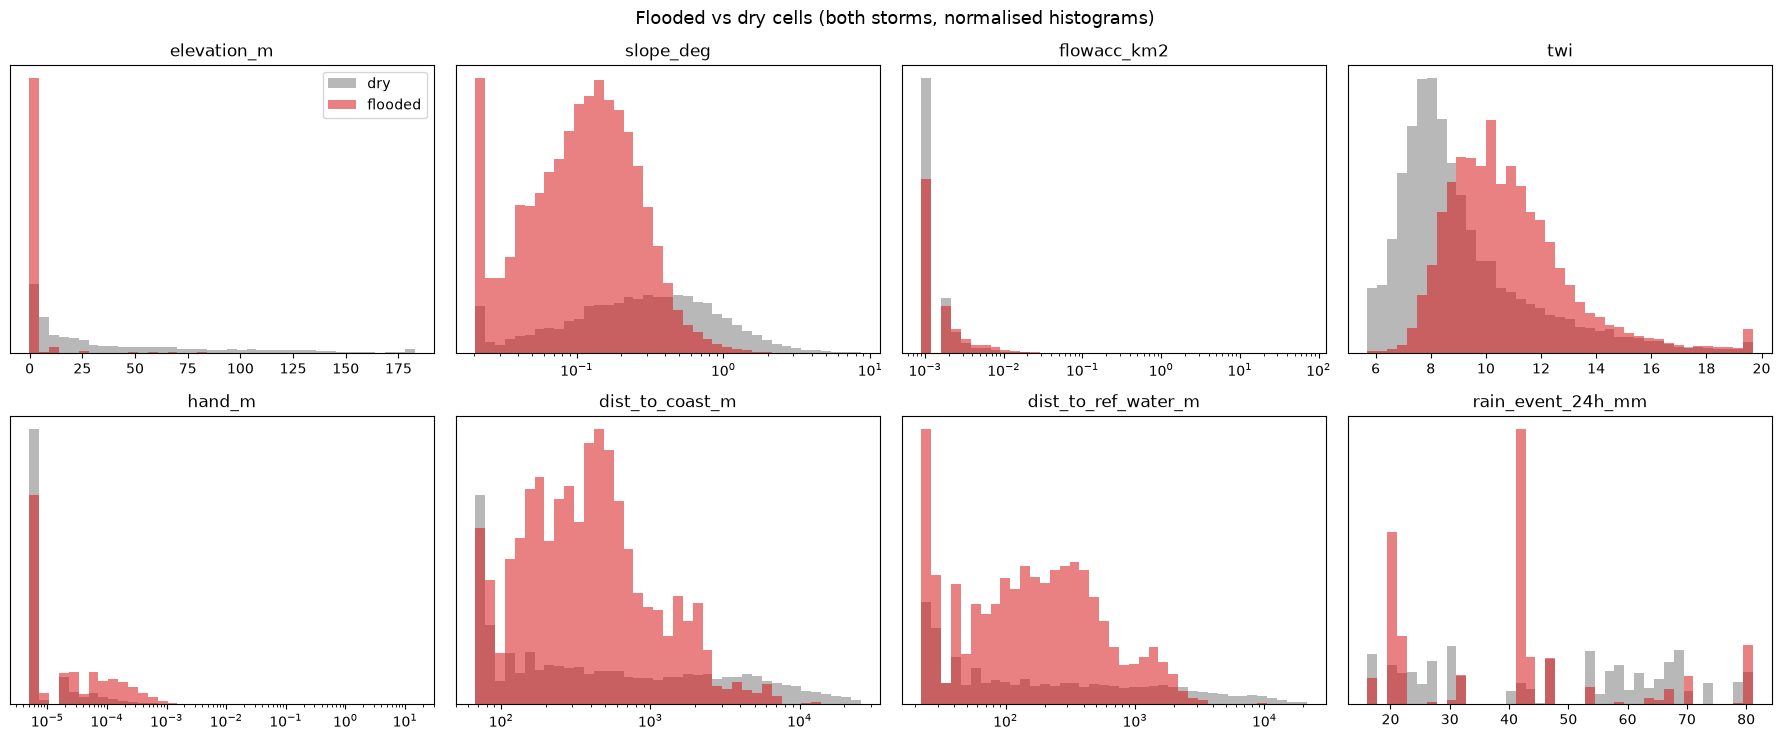

,2017-11-21 dry,2017-11-21 flooded,2022-11-24 dry,2022-11-24 flooded
elevation_m,19.790281,0.493281,20.088127,0.597793
slope_deg,0.912123,0.221678,0.922023,0.223517
flowacc_km2,0.0018,0.0036,0.0018,0.0036
twi,8.454066,10.462805,8.425551,10.422153
hand_m,1.434041,0.00036,1.507725,0.00032
landcover,60.0,60.0,60.0,60.0
dist_to_coast_m,6930.746695,1336.600165,7052.297498,1146.29839
dist_to_ref_water_m,5006.006348,939.707367,5206.802734,630.079346
rain_event_24h_mm,24.145,20.0,61.695,42.024998


In [5]:
SHOW = [("elevation_m", False), ("slope_deg", True), ("flowacc_km2", True), ("twi", False), ("hand_m", True),
        ("dist_to_coast_m", True), ("dist_to_ref_water_m", True), ("rain_event_24h_mm", False)]
fig, axs = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, (col, logx) in zip(axs.ravel(), SHOW):
    v = df[[col, "label"]].dropna()
    lo, hi = v[col].quantile([0.005, 0.995])
    if logx:
        lo = max(lo, v.loc[v[col] > 0, col].min())
        bins = np.logspace(np.log10(lo), np.log10(hi), 40); ax.set_xscale("log")
    else:
        bins = np.linspace(lo, hi, 40)
    for lab, colr, name in ((0, "#7f7f7f", "dry"), (1, "#d7191c", "flooded")):
        ax.hist(v.loc[v.label == lab, col].clip(lo, hi), bins=bins, alpha=0.55, color=colr, label=name, density=True)
    ax.set_title(col); ax.set_yticks([])
axs[0, 0].legend()
fig.suptitle("Flooded vs dry cells (both storms, normalised histograms)", fontsize=13)
plt.tight_layout(); plt.show()

# the same comparison as numbers: medians per storm and class
med = df.groupby(["storm", "label"])[PLACE + ["rain_event_24h_mm"]].median().T
med.columns = [f"{s} {'flooded' if l else 'dry'}" for s, l in med.columns]
med.round(3)

### 1.5 Correlation between the inputs
Finds inputs that carry the same information, which matters when reading feature importance.

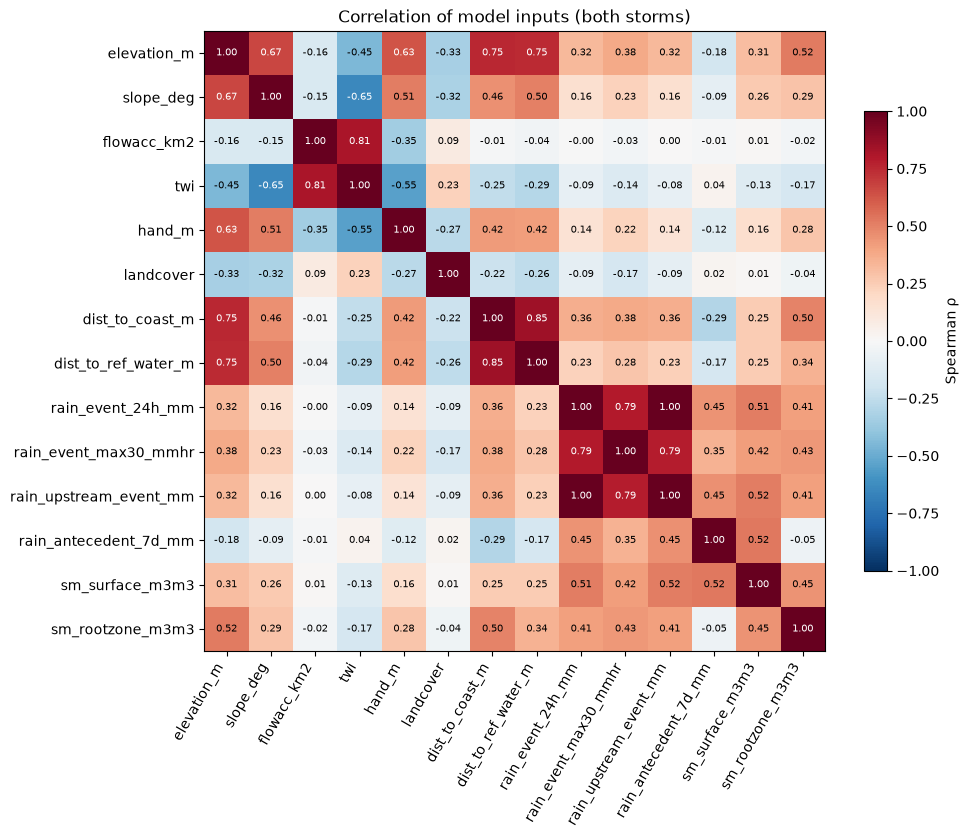

strongest correlations (|ρ| >= 0.8):
rain_event_24h_mm  rain_upstream_event_mm    1.00
dist_to_coast_m    dist_to_ref_water_m       0.85
flowacc_km2        twi                       0.81


In [6]:
corr_cols = PLACE + WEATHER
corr = df[corr_cols].astype("float64").corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right"); ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, shrink=0.7, label="Spearman ρ")
ax.set_title("Correlation of model inputs (both storms)")
plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print("strongest correlations (|ρ| >= 0.8):")
print(pairs[pairs.abs() >= 0.8].sort_values(key=abs, ascending=False).round(2).to_string())

### 1.6 Map of the samples per storm
Shows where the flooded (red) and dry (grey) cells are.

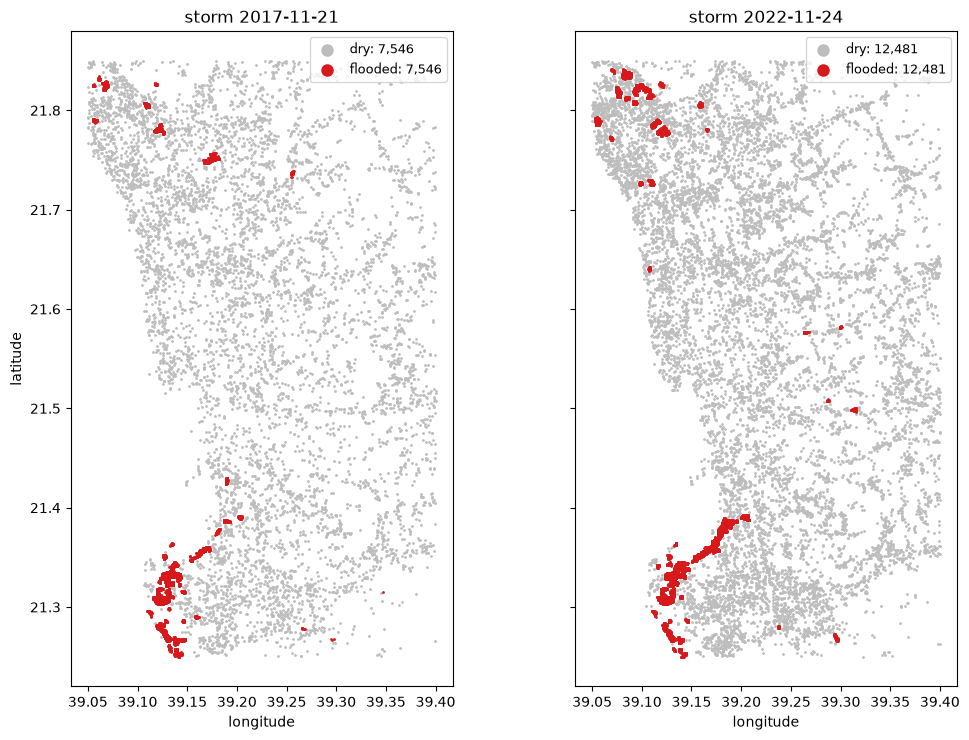

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, (storm, d) in zip(axs, df.groupby("storm")):
    for lab, colr, name in ((0, "#bdbdbd", "dry"), (1, "#d7191c", "flooded")):
        s = d[d.label == lab]
        ax.scatter(s.lon, s.lat, s=1, c=colr, label=f"{name}: {len(s):,}", rasterized=True)
    ax.set_title(f"storm {storm}"); ax.set_xlabel("longitude"); ax.set_aspect("equal")
    ax.legend(loc="upper right", markerscale=8, fontsize=9)
axs[0].set_ylabel("latitude")
plt.tight_layout(); plt.show()

### 1.7 Overlap between the two storms
Two independent radar images, five years apart: if both flag the same places, the labels are real and not noise.

In [8]:
pos = {s: set(d.loc[d.label == 1, "cell_id"]) for s, d in df.groupby("storm")}
a, b = pos["2017-11-21"], pos["2022-11-24"]
both = a & b
print(f"flooded cells 2017: {len(a):,} | 2022: {len(b):,} | flooded in BOTH storms: {len(both):,}")
print(f"  {len(both) / len(a):.0%} of the 2017 flooded cells also flooded in 2022")
print(f"  {len(both) / len(b):.0%} of the 2022 flooded cells also flooded in 2017")

# cells present in both storms with opposite labels (flooded in one, dry in the other)
lab = df.pivot_table(index="cell_id", columns="storm", values="label")
two = lab.dropna()
print(f"cells sampled in both storms: {len(two):,}; with opposite labels: {int((two.iloc[:, 0] != two.iloc[:, 1]).sum())}")

# chance level: how often would a random flooded cell of 2017 be flooded in 2022?
import json
aoi_cells = json.loads((ROOT / "data/processed/build_summary.json").read_text())["aoi_cells"]
print(f"for comparison, the 2022 flooded cells cover only {len(b) / aoi_cells:.1%} of the {aoi_cells:,} study-area cells:")
print(f"  if 2017 flooding were unrelated to 2022, only about {len(a) * len(b) / aoi_cells:.0f} cells would overlap by chance")

flooded cells 2017: 7,546 | 2022: 12,481 | flooded in BOTH storms: 5,166
  68% of the 2017 flooded cells also flooded in 2022
  41% of the 2022 flooded cells also flooded in 2017
cells sampled in both storms: 5,456; with opposite labels: 81
for comparison, the 2022 flooded cells cover only 0.5% of the 2,674,353 study-area cells:
  if 2017 flooding were unrelated to 2022, only about 35 cells would overlap by chance


## 2. Models
All models use only allowed inputs (`use_as_model_input = yes`).

| model | inputs | role |
|---|---|---|
| Elevation only | `elevation_m` (no fitting) | baseline: "low ground floods" |
| Logistic regression — place | place features | simple model |
| **Random Forest — place** | place features | **main model** |
| Logistic regression / Random Forest — place + weather | place + weather | comparison |

In [9]:
LOG = ["flowacc_km2", "hand_m", "dist_to_coast_m", "dist_to_ref_water_m", "slope_deg"]

def design(d, cols):
    """Numeric matrix for the given columns (land cover as a float code)."""
    X = d[cols].copy()
    if "landcover" in X:
        X["landcover"] = X["landcover"].astype("float64")
    return X.astype("float64")

def logreg(cols):
    num = [c for c in cols if c != "landcover"]
    pre = ColumnTransformer([
        ("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p), StandardScaler()),
         [c for c in num if c in LOG]),
        ("lin", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), [c for c in num if c not in LOG]),
        ("lc", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), ["landcover"]),
    ])
    return make_pipeline(pre, LogisticRegression(max_iter=2000))

def forest(**kw):
    return RandomForestClassifier(random_state=SEED, n_jobs=-1, **kw)

MODELS = {
    "Elevation only":                  (None, ["elevation_m"]),
    "Logistic regression — place":     (lambda: logreg(PLACE), PLACE),
    "Random Forest — place":           (lambda: forest(), PLACE),
    "Logistic regression — place + weather": (lambda: logreg(PLACE + WEATHER), PLACE + WEATHER),
    "Random Forest — place + weather": (lambda: forest(), PLACE + WEATHER),
}

## 3. Evaluation
Spatial cross-validation: 5 folds grouped by `block_id`, so each test fold contains only unseen places.
First, a check that no cell or block appears in both training and test.

In [10]:
def spatial_folds(d):
    return list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(d, d.label, groups=d.block_id))

def random_folds(d):
    return list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(d, d.label))

for name, d in (("default file", df), ("elevation-matched file", em)):
    leaks_cell = leaks_block = 0
    for tr, te in spatial_folds(d):
        leaks_cell += len(set(d.cell_id.iloc[tr]) & set(d.cell_id.iloc[te]))
        leaks_block += len(set(d.block_id.iloc[tr]) & set(d.block_id.iloc[te]))
    print(f"{name}: cells in both train and test = {leaks_cell}, blocks in both = {leaks_block}")
    assert leaks_cell == 0 and leaks_block == 0

tr, te = random_folds(df)[0]
print(f"random K-fold, fold 1 (for contrast): {len(set(df.cell_id.iloc[tr]) & set(df.cell_id.iloc[te])):,} cells "
      f"and {len(set(df.block_id.iloc[tr]) & set(df.block_id.iloc[te])):,} blocks shared between train and test")

default file: cells in both train and test = 0, blocks in both = 0


elevation-matched file: cells in both train and test = 0, blocks in both = 0
random K-fold, fold 1 (for contrast): 1,722 cells and 1,392 blocks shared between train and test


Every model on three set-ups: the main file, the elevation-matched file (harder: dry cells at the same
heights as flooded ones), and random K-fold (only to show how much it inflates scores).

In [11]:
def evaluate(d, folds, name, factory, cols):
    X, y = design(d, cols), d.label.to_numpy()
    out = {"roc": [], "pr": [], "roc_train": []}
    for tr, te in folds:
        if factory is None:                                    # elevation-only baseline: no fitting
            p_te, p_tr = -X.iloc[te, 0], -X.iloc[tr, 0]
        else:
            m = factory().fit(X.iloc[tr], y[tr])
            p_te, p_tr = m.predict_proba(X.iloc[te])[:, 1], m.predict_proba(X.iloc[tr])[:, 1]
        out["roc"].append(roc_auc_score(y[te], p_te))
        out["pr"].append(average_precision_score(y[te], p_te))
        out["roc_train"].append(roc_auc_score(y[tr], p_tr))
    return {"model": name, "ROC-AUC": np.mean(out["roc"]), "± (folds)": np.std(out["roc"]),
            "PR-AUC": np.mean(out["pr"]), "train ROC-AUC": np.mean(out["roc_train"])}

SETUPS = [("1 spatial CV — default file (main)", df, spatial_folds(df)),
          ("2 spatial CV — elevation-matched file", em, spatial_folds(em)),
          ("3 random K-fold — default file (inflated, for contrast)", df, random_folds(df))]
rows = []
for setup, d, folds in SETUPS:
    for name, (factory, cols) in MODELS.items():
        rows.append({"set-up": setup, **evaluate(d, folds, name, factory, cols)})
res = pd.DataFrame(rows)
summary = res.drop(columns="train ROC-AUC").set_index(["set-up", "model"]).round(3)
summary

ROC-AUC  \
set-up                                             model                                            
1 spatial CV — default file (main)                 Elevation only                           0.961   
                                                   Logistic regression — place              0.944   
                                                   Random Forest — place                    0.978   
                                                   Logistic regression — place + weather    0.948   
                                                   Random Forest — place + weather          0.978   
2 spatial CV — elevation-matched file              Elevation only                           0.586   
                                                   Logistic regression — place              0.760   
                                                   Random Forest — place                    0.867   
                                                   Logistic regression — place + weather    0.785   
                                                   Random Forest — place + weather          0.908   
3 random K-fold — default file (inflated, for c... Elevation only                           0.961   
                                                   Logistic regression — place              0.947   
                                                   Random Forest — place                    0.995   
                                                   Logistic regression — place + weather    0.954   
                                                   Random Forest — place + weather          0.999   

                                                                                          ± (folds)  \
set-up                                             model                                              
1 spatial CV — default file (main)                 Elevation only                             0.013   
                                                   Logistic regression — place                0.012   
                                                   Random Forest — place                      0.011   
                                                   Logistic regression — place + weather      0.015   
                                                   Random Forest — place + weather            0.016   
2 spatial CV — elevation-matched file              Elevation only                             0.092   
                                                   Logistic regression — place                0.044   
                                                   Random Forest — place                      0.030   
                                                   Logistic regression — place + weather      0.043   
                                                   Random Forest — place + weather            0.028   
3 random K-fold — default file (inflated, for c... Elevation only                             0.002   
                                                   Logistic regression — place                0.002   
                                                   Random Forest — place                      0.001   
                                                   Logistic regression — place + weather      0.002   
                                                   Random Forest — place + weather            0.000   

                                                                                          PR-AUC  
set-up                                             model                                          
1 spatial CV — default file (main)                 Elevation only                          0.961  
                                                   Logistic regression — place             0.932  
                                                   Random Forest — place                   0.978  
                                                   Logistic regression — place + weather   0.943  
                          

## 4. Problem checks
### 4.1 Overfitting
Compares training and test scores; a large gap means the model memorises places. A limited Random Forest
(`max_depth=10`, `min_samples_leaf=20`) tests whether the gap can be reduced.

In [12]:
over = []
for setup, d, folds in SETUPS[:2]:
    for name, factory in (("Logistic regression — place", lambda: logreg(PLACE)),
                          ("Random Forest — place (default)", lambda: forest()),
                          ("Random Forest — place (limited)", lambda: forest(max_depth=10, min_samples_leaf=20))):
        r = evaluate(d, folds, name, factory, PLACE)
        over.append({"set-up": setup, "model": name, "train ROC-AUC": r["train ROC-AUC"], "test ROC-AUC": r["ROC-AUC"],
                     "gap": r["train ROC-AUC"] - r["ROC-AUC"], "test PR-AUC": r["PR-AUC"]})
over = pd.DataFrame(over).set_index(["set-up", "model"]).round(3)
over

train ROC-AUC  \
set-up                                model                                            
1 spatial CV — default file (main)    Logistic regression — place              0.947   
                                      Random Forest — place (default)          1.000   
                                      Random Forest — place (limited)          0.994   
2 spatial CV — elevation-matched file Logistic regression — place              0.781   
                                      Random Forest — place (default)          0.998   
                                      Random Forest — place (limited)          0.944   

                                                                       test ROC-AUC  \
set-up                                model                                           
1 spatial CV — default file (main)    Logistic regression — place             0.944   
                                      Random Forest — place (default)         0.978   
                                      Random Forest — place (limited)         0.978   
2 spatial CV — elevation-matched file Logistic regression — place             0.760   
                                      Random Forest — place (default)         0.867   
                                      Random Forest — place (limited)         0.851   

                                                                         gap  \
set-up                                model                                    
1 spatial CV — default file (main)    Logistic regression — place      0.003   
                                      Random Forest — place (default)  0.022   
                                      Random Forest — place (limited)  0.016   
2 spatial CV — elevation-matched file Logistic regression — place      0.021   
                                      Random Forest — place (default)  0.130   
                                      Random Forest — place (limited)  0.092   

                                                                       test PR-AUC  
set-up                                model                                         
1 spatial CV — default file (main)    Logistic regression — place            0.932  
                                      Random Forest — place (default)        0.978  
                                      Random Forest — place (limited)        0.979  
2 spatial CV — elevation-matched file Logistic regression — place            0.751  
                                      Random Forest — place (default)        0.886  
                                      Random Forest — place (limited)        0.874

### 4.2 Leakage
Confirms that no "do not use" column is an input and flags any score that looks too good to be true (≥ 0.99).

In [13]:
used = set(PLACE + WEATHER)
bad = sorted(used & set(DO_NOT_USE))
print("'do not use' columns among the inputs:", bad or "none")
print("examples of excluded columns:", ", ".join(c for c in ("s2_water_confirmed", "flood_fraction", "hand_ref_is_sea",
      "label_obs_utc", "event_id", "block_id", "lon", "lat", "landcover_year_gap") if c in DO_NOT_USE))

sp = res[res["set-up"].str.startswith(("1", "2"))]
flag = sp[sp["ROC-AUC"] >= 0.99]
print("\nspatial-CV scores >= 0.99:", "none" if flag.empty else flag[["set-up", "model", "ROC-AUC"]].to_string())
rk = res[res["set-up"].str.startswith("3")].set_index("model")["ROC-AUC"]
sm = res[res["set-up"].str.startswith("1")].set_index("model")["ROC-AUC"]
print("\ninflation of random K-fold over spatial CV (ROC-AUC):")
print((rk - sm).round(3).to_string())

'do not use' columns among the inputs: none
examples of excluded columns: s2_water_confirmed, flood_fraction, hand_ref_is_sea, label_obs_utc, event_id, block_id, lon, lat, landcover_year_gap

spatial-CV scores >= 0.99: none

inflation of random K-fold over spatial CV (ROC-AUC):
model
Elevation only                          -0.000
Logistic regression — place              0.003
Random Forest — place                    0.017
Logistic regression — place + weather    0.006
Random Forest — place + weather          0.020


**Stricter test — larger blocks.** Flooded cells sit in a few clusters, so 1 km blocks may still have training
neighbours from the same cluster. Repeating the main model with 5 km and 10 km blocks shows the skill on truly new areas.

In [14]:
def coarse_blocks(d, km):
    return (d.x // (km * 1000)).astype(int).astype(str) + "_" + (d.y // (km * 1000)).astype(int).astype(str)

strict = []
for fname, d in (("default file", df), ("elevation-matched file", em)):
    X, y = design(d, PLACE), d.label.to_numpy()
    for km in (1, 5, 10):
        g = coarse_blocks(d, km)
        rf_s, el_s = [], []
        for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, groups=g):
            m = forest().fit(X.iloc[tr], y[tr])
            rf_s.append(roc_auc_score(y[te], m.predict_proba(X.iloc[te])[:, 1]))
            el_s.append(roc_auc_score(y[te], -d.elevation_m.to_numpy()[te]))
        strict.append({"file": fname, "block size": f"{km} km", "blocks": g.nunique(),
                       "RF place ROC-AUC": np.mean(rf_s), "± (folds)": np.std(rf_s),
                       "elevation-only ROC-AUC": np.mean(el_s), "RF gain over elevation": np.mean(rf_s) - np.mean(el_s)})
pd.DataFrame(strict).set_index(["file", "block size"]).round(3)

blocks  RF place ROC-AUC  ± (folds)  \
file                   block size                                        
default file           1 km          1823             0.978      0.011   
                       5 km           106             0.949      0.048   
                       10 km           34             0.912      0.062   
elevation-matched file 1 km           936             0.867      0.030   
                       5 km            74             0.722      0.114   
                       10 km           23             0.668      0.103   

                                   elevation-only ROC-AUC  \
file                   block size                           
default file           1 km                         0.961   
                       5 km                         0.946   
                       10 km                        0.909   
elevation-matched file 1 km                         0.586   
                       5 km                         0.519   
                       10 km                        0.480   

                                   RF gain over elevation  
file                   block size                          
default file           1 km                         0.017  
                       5 km                         0.003  
                       10 km                        0.002  
elevation-matched file 1 km                         0.281  
                       5 km                         0.204  
                       10 km                        0.189

### 4.3 What drives the predictions
Permutation importance on the test folds: how much the test score drops when one feature is shuffled.

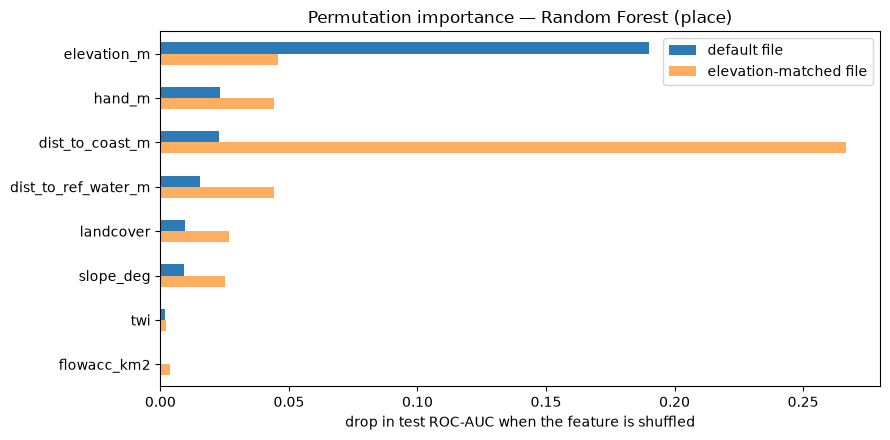

,default file,elevation-matched file
elevation_m,0.190,0.046
hand_m,0.023,0.044
dist_to_coast_m,0.023,0.267
dist_to_ref_water_m,0.015,0.044
landcover,0.010,0.027
slope_deg,0.009,0.025
twi,0.002,0.002
flowacc_km2,0.000,0.004


In [15]:
def perm_importance(d, cols):
    X, y = design(d, cols), d.label.to_numpy()
    imps = []
    for tr, te in spatial_folds(d):
        m = forest().fit(X.iloc[tr], y[tr])
        r = permutation_importance(m, X.iloc[te], y[te], scoring="roc_auc", n_repeats=5, random_state=SEED)
        imps.append(r.importances_mean)
    return pd.Series(np.mean(imps, axis=0), index=cols)

imp = pd.DataFrame({"default file": perm_importance(df, PLACE), "elevation-matched file": perm_importance(em, PLACE)})
imp = imp.sort_values("default file", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
imp.plot.barh(ax=ax, color=["#2c7bb6", "#fdae61"]); ax.invert_yaxis()
ax.set_xlabel("drop in test ROC-AUC when the feature is shuffled"); ax.set_title("Permutation importance — Random Forest (place)")
plt.tight_layout(); plt.show()
imp.round(3)

## 5. Conclusions

- **Data is clean:** balanced per storm, few missing values, no leakage, no place shared between training and test.
- **Labels are consistent:** 5,166 cells flooded in both storms, against about 35 expected by chance.
- **Elevation alone is very strong** (0.961); the full model adds little on the main file (0.978).
- **The model learns more than elevation:** on the elevation-matched file it reaches 0.867 vs 0.586 for
  elevation alone, mostly through distance to the coast.
- **On genuinely new areas** (5 km and 10 km blocks) the skill is moderate.
- **Rain and soil moisture act as location markers**, not as a real rain effect.
- **Main limitations:** few flooded clusters, the radar cannot see the dense city, coarse rain data, and only two storms.

**Answer to "where":** low-lying ground near the coast and near existing water is most susceptible; with two
storms and a few flooded clusters, the data cannot yet show *why* beyond that, or how well this transfers to
new areas.